<a href="https://colab.research.google.com/github/Pedro050723/Projeto-Pratico-2.1-Pedro-Miranda/blob/main/Projeto_Pr%C3%A1tico2_1_RNA_PEDRO_HENRIQUE_MIRANDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Redes Neurais Artificiais – Projeto Prático 2.1

**Aluno:** Pedro Henrique Miranda do Valle

## Parte I – Perceptron em um problema linearmente separável

**Objetivo:** implementar o algoritmo de treinamento do neurônio Perceptron (Rosenblatt) e usá-lo para separar duas classes de pontos do arquivo `dataAll20262.txt`.

##Importando as bibliotecas

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [7]:
Caminho = "dataAll20262.txt"

dados = np.load(Caminho)            # lê o ndarray salvo em binário
print("Shape original:", dados.shape)

dados = dados.reshape(-1, 3)        # (m, 1, 3) -> (m, 3)




print("Shape após reshape:", dados.shape)

print("\nPrimeiras 5 linhas (x1, x2, yd):")
print(dados[:5])

Shape original: (1000, 1, 3)
Shape após reshape: (1000, 3)

Primeiras 5 linhas (x1, x2, yd):
[[ 547.91209711 -122.2431205     1.        ]
 [ 717.19583982  394.73605812    0.        ]
 [-811.64530422  951.24470327    0.        ]
 [ 522.27940398  572.12861055    0.        ]
 [-743.77273465  -99.22812421    0.        ]]


In [8]:
X_orig = dados[:, :2]          # todas as linhas, colunas 0 e 1  -> (x1, x2)
y_d    = dados[:, 2]           # todas as linhas, coluna 2        -> rótulo

m = X_orig.shape[0]
print("Número de exemplos:", m)

classes, contagens = np.unique(y_d, return_counts=True)
for c, n in zip(classes, contagens):
    print(f"Classe {int(c)}: {n} exemplos")

Número de exemplos: 1000
Classe 0: 500 exemplos
Classe 1: 500 exemplos


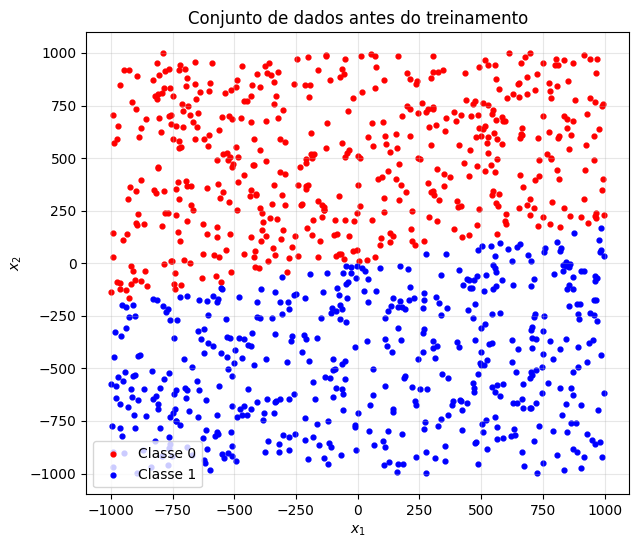

In [9]:
plt.figure(figsize=(7, 6))
plt.scatter(X_orig[y_d == 0, 0], X_orig[y_d == 0, 1], c="red",  s=12, label="Classe 0")
plt.scatter(X_orig[y_d == 1, 0], X_orig[y_d == 1, 1], c="blue", s=12, label="Classe 1")
plt.xlabel("$x_1$"); plt.ylabel("$x_2$")
plt.title("Conjunto de dados antes do treinamento")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

##Preparação da entrada: coluna de *bias* (*viés*)

In [10]:
coluna_bias = np.ones((m, 1))                 # coluna de 1's, shape (m, 1)
X = np.hstack([coluna_bias, X_orig])          # junta lado a lado -> (m, 3)

print("Shape de X:", X.shape)
print("Primeiras 3 linhas de X  [1, x1, x2]:")
print(X[:3])

Shape de X: (1000, 3)
Primeiras 3 linhas de X  [1, x1, x2]:
[[   1.          547.91209711 -122.2431205 ]
 [   1.          717.19583982  394.73605812]
 [   1.         -811.64530422  951.24470327]]


## Hiperparâmetros e pesos iniciais

Exigências do enunciado:

- taxa de aprendizado $\eta = 0{,}1$;
- ativação degrau com limiar $\vartheta = 0$;
- pesos iniciais $w_i \sim U(-0{,}5, +0{,}5)$ (distribuição uniforme), **impressos no início**.


In [12]:
ETA = 0.1                 # taxa de aprendizado
Limiar = 0.0              # θ da função degrau
INTERVALO_PESOS = (-0.5, 0.5)
SEMENTE = None              # pode-se optar por um valor fixo para verificação da execução

if SEMENTE is not None:
    np.random.seed(SEMENTE)

# 3 pesos: w0 (bias), w1, w2 — sorteados uniformemente em [-0.5, 0.5)
w_inicial = np.random.uniform(INTERVALO_PESOS[0], INTERVALO_PESOS[1], size=3)

print("Vetor de pesos inicial [w0, w1, w2]:", w_inicial)

Vetor de pesos inicial [w0, w1, w2]: [-0.19964734  0.44228127 -0.11629671]


## A teoria

**Potencial de ativação:** $u = \mathbf{w}\cdot\mathbf{x}$

**Função de ativação degrau** (com $\vartheta = 0$):

$$y = \begin{cases} 1 & \text{se } u \ge 0 \\ 0 & \text{se } u < 0 \end{cases}$$

**Regra de aprendizado do Perceptron** — só altera os pesos quando **erra**:

$$\mathbf{w} \leftarrow \mathbf{w} + \eta\,(y_d - y)\,\mathbf{x}$$

Repare no que $(y_d - y)$ faz:

| $y_d$ | $y$ (obtido) | $y_d - y$ | efeito |
|:-:|:-:|:-:|---|
| 1 | 0 | **+1** | $\mathbf{w}$ se aproxima de $\mathbf{x}$ (aumenta $u$) |
| 0 | 1 | **−1** | $\mathbf{w}$ se afasta de $\mathbf{x}$ (diminui $u$) |
| igual | igual | 0 | nada muda |

**Vocabulário:**

- **Ajuste** = cada vez que o vetor de pesos é modificado (ou seja, cada erro corrigido).
- **Época** = uma passada completa por todos os exemplos de treinamento.
- **Convergência** = uma época inteira **sem nenhum erro**.

##Implementação do Treinamento

In [13]:
def degrau(u, limiar=0.0):
    # Retorna 1 se u >= limiar, senão 0
    return 1 if u >= limiar else 0